# Gate sequences that track the time-optimal $H_{\rm opt}$ trajectory

We optimize a layered circuit

$$
U = \prod_{b=N_B}^{1} \Big[\prod_{j} e^{-i c_{b,j}\, G_j \otimes \sigma_z}\Big]\, R(\theta_b, \phi_b),
\qquad N_B = N K,
$$

so that the oscillator state after every $K$-th block follows the **time-optimal** (brachistochrone) path from the vacuum to a finite-energy GKP logical state. The default generators $G_j$ are the conditional-squeezing pair $G_A = \tfrac{i}{2}(a^2 - a^{\dagger 2})$, $G_B = -\tfrac12(a^2 + a^{\dagger 2})$ (the `R → CS_A → CS_B` block of the original script); conditional displacements (`x`, `p`), conditional rotation (`n`) and conditional Kerr (`kerr`) can be mixed in freely.

**Time-optimal path.** `brachistochrone.quantum_brachistochrone_hamiltonian` gives the rank-2 $H_{\rm opt}$ acting in ${\rm span}\{\ket{0}, \ket{\chi}\}$ with $\ket{\chi} \propto \ket{T} - \braket{0|T}\ket{0}$ and minimum time $t^* = \theta_0 = \arccos|\braket{0|T}|$ (at $\lVert H\rVert = 1$). Up to a global phase,

$$
\ket{g(s)} = \cos(s\theta_0)\ket{0} + \sin(s\theta_0)\ket{\chi}, \qquad |\braket{T|g(s)}|^2 = \cos^2[(1-s)\theta_0].
$$

**Loss** (qubit traced out, or projected on $\ket{g}$):

$$
\mathcal{L} = \sum_{k=1}^{N} w_k \Big[1 - \sum_q |\braket{g(k/N)|\psi_{kK}^{q}}|^2\Big] + \lambda_c \sum_b \lVert p_{b+1} - p_b\rVert^2 + \lambda_\theta \sum_b \theta_b^2 + \lambda_{\rm leak}\,\overline{P}_{\rm leak}.
$$

Matching the *pure* geodesic state at every checkpoint forces the qubit to disentangle at every checkpoint.

**Target** (paper Eq. 4, `TARGET_ENVELOPE="operator"`): $\ket{\mu_L} \propto e^{-\Delta^2 \hat n} \sum_{m \equiv \mu,\, l} e^{-i\pi m l/2} \ket{m\alpha + l\beta}$. Alternatively `"peak"` uses `states.gkp_states` (Gaussian-weighted peaks).

**Optimization.** Many seeds in parallel: `vmap`-batched Adam (`gate_optimization._adam_run`, cosine schedule) over chunks of `SEED_BATCH` seeds, seeded with a greedy layer-by-layer initialization plus jittered copies plus random draws; then L-BFGS-B polish of the best `N_POLISH` seeds. The result is re-validated at a larger Fock cutoff, because truncated generators can be exploited by the optimizer.

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
import time

import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import jaxquantum as jqt
import matplotlib.colors as mpl_colors
import matplotlib.pyplot as plt
import numpy as np
from jax import lax
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.optimize import minimize

from gkp_optimal_control.brachistochrone import quantum_brachistochrone_hamiltonian
from gkp_optimal_control.gate_optimization import adam_run, cosine_schedule
from gkp_optimal_control.operators import cavity_operators, qubit_rotation
from gkp_optimal_control.plotting import plot_wigner, set_plot_style
from gkp_optimal_control.states import coherent_state_vectors, fock_state, gkp_states
from gkp_optimal_control.utils import compute_wigner, to_ket, to_qarray, wigner_trajectory

print(f"JAX devices: {jax.devices()}   backend: {jax.default_backend()}")
assert jnp.zeros(1).dtype == jnp.float64, "jax_enable_x64 must be on"

JAX devices: [CpuDevice(id=0)]   backend: cpu


## Configuration

Every knob lives here. The defaults reproduce the original script (`--D 80 --N 32 --K 3 --Delta 0.35`, Eq. 4 target, $\ket{0_L}$), but with many more seeds.

In [2]:
# ---- target -----------------------------------------------------------------
N_FOCK = 80                    # Fock cutoff D used during optimization
TARGET_ENVELOPE = "operator"   # "operator": e^{-Delta^2 n} sum (paper Eq. 4) | "peak": states.gkp_states
LOGICAL = "0"                  # "0", "1", "+", "-", "+i", "-i"
GKP_DELTA = 0.35
GKP_ALPHA = float(np.sqrt(np.pi / 2))
GKP_BETA = 1j * float(np.sqrt(np.pi / 2))
LATTICE_M = 10                 # "operator": |m|,|l| <= M ; "peak": gkp_states cutoff
TARGET_OVERSAMPLE = 2          # build the target at this multiple of N_FOCK, then truncate

# ---- ansatz -----------------------------------------------------------------
N_CHECK = 32                   # geodesic checkpoints N
K_BLOCKS = 3                   # blocks between checkpoints
GENERATORS = ("sqA", "sqB")    # conditional generators after R(theta, phi): sqA, sqB, x, p, n, kerr
QUBIT_TARGET = "traced"        # "traced": qubit traced out | "ground": project on |g>

# ---- loss -------------------------------------------------------------------
LOSS_TYPE = "infidelity"       # "infidelity" | "log_infidelity" (log of the tracking term)
W_FINAL = 5.0                  # extra weight on the last checkpoint
LAMBDA_CONTROL = 1e-4          # smoothness of consecutive blocks (phase wrapped)
LAMBDA_ROT = 1e-5              # sum theta^2
LAMBDA_LEAK = 0.0              # mean population in top N_LEAK Fock levels, every block
N_LEAK = 5

# ---- optimizer --------------------------------------------------------------
N_SEEDS = 256                  # total seeds (greedy + jittered greedy + random)
SEED_BATCH = 64                # seeds per vmapped Adam call (memory knob)
N_ADAM_ITERS = 3000
PEAK_LR = 0.02
WARMUP_FRAC = 0.05
FINAL_LR_FRAC = 0.02
INIT_SCALE_GEN = 0.15          # std of random generator amplitudes
INIT_SCALE_THETA = 0.1
INIT_SCALE_PHI = 0.05
USE_GREEDY = True
N_GREEDY_JITTER = 15           # extra seeds = greedy + N(0, GREEDY_JITTER)
GREEDY_JITTER = 0.02
N_POLISH = 8                   # L-BFGS-B polish of the best Adam seeds
POLISH_MAXITER = 3000
RNG_SEED = 1
LOAD_PARAMS = "../../figs/timeopt_tracking/params_operator_L0_D80_N32_K3_Delta0.35_sqA-sqB.npy"             # path to a saved .npy (same layout as the original script) to skip optimization

# ---- validation / plots -----------------------------------------------------
N_FOCK_VALIDATE = 120          # re-run the optimized circuit at this cutoff
WIGNER_BOUND = 7.0
WIGNER_POINTS = 201
PATH_FRAMES_PER_GATE = 8       # interpolation for the Fubini-Study arc length
MAKE_MOVIE = False
MOVIE_FRAMES_PER_GATE = 2
MOVIE_POINTS = 121
MOVIE_FPS = 12
USE_TEX = True
OUT_DIR = "../../figs/timeopt_tracking"

In [3]:
N_BLOCKS = N_CHECK * K_BLOCKS
N_GEN = len(GENERATORS)
N_COL = N_GEN + 2                      # [c_1 .. c_G, theta, phi] per block
N_PARAMS = N_BLOCKS * N_COL
OUT_TAG = (f"{TARGET_ENVELOPE}_L{LOGICAL.replace('+', 'p').replace('-', 'm')}_D{N_FOCK}"
           f"_N{N_CHECK}_K{K_BLOCKS}_Delta{GKP_DELTA}_{'-'.join(GENERATORS)}")
os.makedirs(OUT_DIR, exist_ok=True)

set_plot_style()
if not USE_TEX:
    plt.rcParams["text.usetex"] = False

print(f"blocks={N_BLOCKS}  generators={GENERATORS}  params={N_PARAMS}  total gates={N_BLOCKS * (N_GEN + 1)}")
print(f"squeezing: {-10 * np.log10(GKP_DELTA**2):.2f} dB   tag: {OUT_TAG}")

blocks=96  generators=('sqA', 'sqB')  params=384  total gates=288
squeezing: 9.12 dB   tag: operator_L0_D80_N32_K3_Delta0.35_sqA-sqB


## Target state

Eq. (4) is built from `states._coherent_state_vectors` over exactly the script's $(m, l)$ range; `"peak"` calls `states.gkp_states`. Logical combinations use separately normalized $\ket{0_L}, \ket{1_L}$, as in `brachistochrone_gkp_state_prep.ipynb`. The target is built at `TARGET_OVERSAMPLE * D`, truncated to $D$ and renormalized.

In [4]:
LOGICAL_COEFFS = {"0": (1, 0), "1": (0, 1), "+": (1, 1), "-": (1, -1), "+i": (1, 1j), "-i": (1, -1j)}


def logical_pair_operator_envelope(n_fock, alpha, beta, delta, M):
    # paper Eq. (4): e^{-Delta^2 n} sum_{m = mu mod 2, l} e^{-i pi m l / 2} |m alpha + l beta>
    ms = jnp.arange(-M, M + 1)
    m_grid, l_grid = jnp.meshgrid(ms, ms, indexing="ij")
    m_flat, l_flat = m_grid.ravel(), l_grid.ravel()
    peaks = coherent_state_vectors(n_fock, m_flat * alpha + l_flat * beta)     # (M', n_fock)
    phases = jnp.exp(-1j * jnp.pi * m_flat * l_flat / 2)
    envelope = jnp.exp(-(delta**2) * jnp.arange(n_fock))
    out = []
    for mu in (0, 1):
        w = jnp.where((m_flat - mu) % 2 == 0, phases, 0.0)
        v = jnp.sum(w[:, None] * peaks, axis=0) * envelope
        out.append(v / jnp.linalg.norm(v))
    return out


def make_target(n_fock):
    n_big = TARGET_OVERSAMPLE * n_fock
    if TARGET_ENVELOPE == "operator":
        g0, g1 = logical_pair_operator_envelope(n_big, GKP_ALPHA, GKP_BETA, GKP_DELTA, LATTICE_M)
    elif TARGET_ENVELOPE == "peak":
        q0, q1 = gkp_states(n_big, GKP_ALPHA, GKP_BETA, GKP_DELTA, LATTICE_M)
        g0, g1 = to_ket(q0), to_ket(q1)
    else:
        raise ValueError(f"unknown TARGET_ENVELOPE {TARGET_ENVELOPE!r}")
    c0, c1 = LOGICAL_COEFFS[LOGICAL]
    big = c0 * g0 + c1 * g1
    big = big / jnp.linalg.norm(big)
    weight = float(jnp.sum(jnp.abs(big[:n_fock]) ** 2))
    return to_ket(big[:n_fock]), weight


target, target_weight = make_target(N_FOCK)
n_bar = float(jnp.sum(jnp.arange(N_FOCK) * jnp.abs(target) ** 2))
print(f"target weight inside D={N_FOCK}: {target_weight:.10f}   <n> = {n_bar:.3f}")

target weight inside D=80: 0.9999999978   <n> = 3.519


## Time-optimal geodesic from `quantum_brachistochrone_hamiltonian`

$\ket{g(s)} = e^{-i H_{\rm opt} s t^*}\ket{0}$, evaluated through one `eigh` of $H_{\rm opt}$. We cross-check against the closed form $\cos(s\theta_0)\ket{0} + \sin(s\theta_0)\ket{\chi}$ and the endpoint fidelity.

In [5]:
def make_geodesic(target_ket):
    n_fock = target_ket.shape[0]
    vac_ket = fock_state(n_fock, 0)
    h_opt, t_min = quantum_brachistochrone_hamiltonian(
        vac_ket, to_ket(target_ket), energy_bound=1.0
    )
    h = h_opt.data if isinstance(h_opt, jqt.Qarray) else jnp.asarray(h_opt)
    w, v = jnp.linalg.eigh(h)
    vac_coeffs = v.conj().T[:, 0]                       # V^dag |0>
    t_min = float(t_min)

    def geodesic(s):
        s = jnp.atleast_1d(jnp.asarray(s, dtype=jnp.float64))
        ph = jnp.exp(-1j * jnp.outer(s * t_min, w))      # (S, D)
        return (ph * vac_coeffs[None, :]) @ v.T          # (S, D)

    return h, t_min, geodesic


H_opt, theta0, geodesic = make_geodesic(target)
s_ck = jnp.arange(N_CHECK + 1) / N_CHECK
GEO = geodesic(s_ck)                                       # (N+1, D)
F_geo_target = np.cos(theta0 * (1 - np.asarray(s_ck))) ** 2

# closed-form cross-check
vac = fock_state(N_FOCK, 0)
T_ph = target * jnp.exp(-1j * jnp.angle(target[0]))
chi = (T_ph - T_ph[0] * vac) / jnp.linalg.norm(T_ph - T_ph[0] * vac)
closed = jnp.cos(theta0 * s_ck)[:, None] * vac + jnp.sin(theta0 * s_ck)[:, None] * chi
err_closed = float(jnp.max(1 - jnp.abs(jnp.sum(closed.conj() * GEO, axis=1)) ** 2))
err_end = 1 - float(jnp.abs(jnp.vdot(target, GEO[-1])) ** 2)
err_curve = float(np.max(np.abs(np.asarray(jnp.abs(GEO @ target.conj()) ** 2) - F_geo_target)))
print(f"|<0|T>|^2 = {np.cos(theta0)**2:.4e}   theta0 = t* = {theta0:.6f} rad")
print(f"closed-form mismatch {err_closed:.1e}   endpoint infidelity {err_end:.1e}   cos^2 curve {err_curve:.1e}")
np.save(os.path.join(OUT_DIR, f"Hopt_{OUT_TAG}.npy"), np.asarray(H_opt))

|<0|T>|^2 = 4.3645e-01   theta0 = t* = 0.849116 rad
closed-form mismatch 6.7e-16   endpoint infidelity 2.2e-16   cos^2 curve 1.2e-15


## Circuit ansatz

Each conditional gate $e^{-i c\, G\otimes\sigma_z}$ is applied through a precomputed `eigh` of the truncated generator, so it is exactly unitary on the truncated space and differentiates through a diagonal exponential. The state is carried as qubit blocks $(\psi_g, \psi_e)$ of shape `(2, D)`, as in `gate_optimization`; rotations use `gate_optimization.qubit_rotation` (identical convention to the script's `rot`).

In [6]:
def generator_matrix(name, n_fock):
    a, adag, num = cavity_operators(n_fock)
    r2 = jnp.sqrt(2.0)
    lib = {
        "sqA": lambda: 1j * (a @ a - adag @ adag) / 2,     # script: eigh(1j * A)
        "sqB": lambda: -(a @ a + adag @ adag) / 2,         # script: eigh(1j * B)
        "x": lambda: (a + adag) / r2,                      # conditional p-displacement
        "p": lambda: 1j * (adag - a) / r2,                 # conditional x-displacement
        "n": lambda: num,                                  # conditional rotation
        "kerr": lambda: adag @ adag @ a @ a / 2,           # conditional Kerr
    }
    if name not in lib:
        raise ValueError(f"unknown generator {name!r}; choose from {sorted(lib)}")
    return lib[name]()


class Ansatz:
    def __init__(self, n_fock, generators, n_blocks):
        self.n_fock, self.generators, self.n_blocks = n_fock, tuple(generators), n_blocks
        self.n_gen = len(generators)
        self.n_col = self.n_gen + 2
        eig = [jnp.linalg.eigh(generator_matrix(g, n_fock)) for g in generators]
        self.w = jnp.stack([e[0] for e in eig])            # (G, D)
        self.v = jnp.stack([e[1] for e in eig])            # (G, D, D)
        self.signs = jnp.array([1.0, -1.0])                # sigma_z on (|g>, |e>)

    def psi_init(self):
        return jnp.zeros((2, self.n_fock), dtype=jnp.complex128).at[0, 0].set(1.0)

    def apply_cond(self, psi, j, c):
        # exp(-i c G_j sigma_z) on (2, D) blocks
        ph = jnp.exp(-1j * c * self.signs[:, None] * self.w[j][None, :])
        return ((psi @ self.v[j].conj()) * ph) @ self.v[j].T

    def apply_block(self, psi, p):
        psi = qubit_rotation(p[self.n_gen], p[self.n_gen + 1]) @ psi
        for j in range(self.n_gen):
            psi = self.apply_cond(psi, j, p[j])
        return psi

    def trajectory(self, flat):
        # states after every block, including the initial state: (NB + 1, 2, D)
        P = jnp.reshape(flat, (self.n_blocks, self.n_col))
        psi0 = self.psi_init()

        def step(psi, p):
            psi = self.apply_block(psi, p)
            return psi, psi

        _, states = lax.scan(step, psi0, P)
        return jnp.concatenate([psi0[None], states], axis=0)


def osc_fidelity(g, psi, qubit_target=QUBIT_TARGET):
    # g (..., D), psi (..., 2, D)
    ov = jnp.einsum("...d,...qd->...q", jnp.conj(g), psi)
    if qubit_target == "ground":
        return jnp.abs(ov[..., 0]) ** 2
    return jnp.sum(jnp.abs(ov) ** 2, axis=-1)


def qubit_purity(psi):
    rq = psi @ psi.conj().T
    return float(np.real(np.trace(np.asarray(rq @ rq))))


ansatz = Ansatz(N_FOCK, GENERATORS, N_BLOCKS)

## Loss

In [7]:
CK_IDX = np.arange(1, N_CHECK + 1) * K_BLOCKS            # block index of each checkpoint
WK = np.ones(N_CHECK + 1) / N_CHECK
WK[N_CHECK] = W_FINAL
WK[0] = 0.0


def make_loss(ansatz, geo, target_ket):
    wk = jnp.asarray(WK[1:])

    def parts(flat):
        states = ansatz.trajectory(flat)
        f_ck = osc_fidelity(geo[1:], states[CK_IDX])
        P = jnp.reshape(flat, (ansatz.n_blocks, ansatz.n_col))
        d = P[1:] - P[:-1]
        d = jnp.concatenate([d[:, :-1], (d[:, -1:] + jnp.pi) % (2 * jnp.pi) - jnp.pi], axis=1)
        smooth = jnp.sum(d**2)
        rot = jnp.sum(P[:, ansatz.n_gen] ** 2)
        leak = jnp.mean(jnp.sum(jnp.abs(states[1:, :, -N_LEAK:]) ** 2, axis=(-1, -2)))
        return states, f_ck, smooth, rot, leak

    def loss(flat):
        _, f_ck, smooth, rot, leak = parts(flat)
        track = jnp.sum(wk * (1.0 - f_ck))
        if LOSS_TYPE == "log_infidelity":
            track = jnp.log(track + 1e-14)
        return track + LAMBDA_CONTROL * smooth + LAMBDA_ROT * rot + LAMBDA_LEAK * leak

    def diagnostics(flat):
        states, f_ck, _, _, leak = parts(flat)
        f_target = osc_fidelity(target_ket, states[-1])
        return loss(flat), jnp.min(f_ck), f_target, leak

    return loss, diagnostics


loss_fn, diagnostics = make_loss(ansatz, GEO, target)
loss_and_grad = jax.value_and_grad(loss_fn)
loss_and_grad_jit = jax.jit(loss_and_grad)

Gradient check against central finite differences (as in the script).

In [8]:
_rc = np.random.default_rng(123)
_pc = jnp.asarray(_rc.normal(0, 0.2, N_PARAMS))
_l0, _g0 = loss_and_grad_jit(_pc)
_err = 0.0
for _j in _rc.choice(N_PARAMS, 6, replace=False):
    _e = np.zeros(N_PARAMS); _e[_j] = 1e-6
    _fd = (float(loss_fn(_pc + _e)) - float(loss_fn(_pc - _e))) / 2e-6
    _err = max(_err, abs(_fd - float(_g0[_j])))
print(f"loss at random point: {float(_l0):.6f}   max |grad - FD| = {_err:.3e}")

loss at random point: 5.502390   max |grad - FD| = 1.629e-09


## Seeds

Greedy initialization: block $b$ maximizes the overlap with $\ket{g(b/N_B)}$ given the state after block $b-1$ (BFGS, a few restarts). Seed 0 is the greedy solution, the next `N_GREEDY_JITTER` are jittered copies, the rest are random with the script's scales.

In [9]:
def scipy_fg(vg, *args):
    def f(x):
        v, g = vg(jnp.asarray(x), *args)
        return float(v), np.asarray(g, dtype=np.float64)
    return f


def greedy_init(ansatz, geodesic, rng, n_trials=4, maxiter=60):
    nb, nc = ansatz.n_blocks, ansatz.n_col
    G = geodesic(jnp.arange(1, nb + 1) / nb)
    single = lambda x, psi, g: 1.0 - osc_fidelity(g, ansatz.apply_block(psi, x))
    vg = jax.jit(jax.value_and_grad(single))
    block = jax.jit(ansatz.apply_block)
    psi = ansatz.psi_init()
    P = np.zeros((nb, nc))
    prev = np.zeros(nc)
    for k in range(nb):
        best = None
        for trial in range(n_trials):
            x0 = prev.copy() if trial == 0 else prev + rng.normal(0, 0.1, nc)
            res = minimize(scipy_fg(vg, psi, G[k]), x0, jac=True, method="BFGS",
                           options={"maxiter": maxiter})
            if best is None or res.fun < best.fun:
                best = res
        P[k] = prev = best.x
        psi = block(psi, jnp.asarray(best.x))
    return P.ravel()


RUN_OPT = LOAD_PARAMS is None
if RUN_OPT:
    rng = np.random.default_rng(RNG_SEED)
    seeds = []
    if USE_GREEDY:
        t0 = time.time()
        p_greedy = greedy_init(ansatz, geodesic, rng)
        _, fmin_g, ft_g, _ = diagnostics(jnp.asarray(p_greedy))
        print(f"greedy init: min_k F_geo = {float(fmin_g):.5f}   F_target = {float(ft_g):.6f}   ({time.time()-t0:.1f}s)")
        seeds.append(p_greedy)
        for _ in range(N_GREEDY_JITTER):
            seeds.append(p_greedy + rng.normal(0, GREEDY_JITTER, N_PARAMS))
    n_random = max(N_SEEDS - len(seeds), 0)
    scales = jnp.asarray([INIT_SCALE_GEN] * N_GEN + [INIT_SCALE_THETA, INIT_SCALE_PHI])
    key = jax.random.PRNGKey(RNG_SEED)
    rand = jax.random.normal(key, (n_random, N_BLOCKS, N_COL)) * scales
    init_params = jnp.concatenate(
        [jnp.asarray(np.array(seeds)).reshape(-1, N_PARAMS), jnp.reshape(rand, (n_random, N_PARAMS))], axis=0
    )[:N_SEEDS]
    seed_kind = np.array((["greedy"] if USE_GREEDY else []) + ["jitter"] * (N_GREEDY_JITTER if USE_GREEDY else 0)
                         + ["random"] * n_random)[:N_SEEDS]
    print(f"{init_params.shape[0]} seeds: " + ", ".join(f"{k}={np.sum(seed_kind == k)}" for k in np.unique(seed_kind)))

## Batched Adam over all seeds

One `jit(vmap(_adam_run))` per chunk of `SEED_BATCH` seeds; the last chunk is padded so it reuses the compiled kernel.

In [10]:
if RUN_OPT:
    lr_at = cosine_schedule(N_ADAM_ITERS, PEAK_LR, WARMUP_FRAC, FINAL_LR_FRAC)
    adam_batch = jax.jit(jax.vmap(lambda p0: adam_run(loss_and_grad, p0, N_ADAM_ITERS, lr_at)))
    diag_batch = jax.jit(jax.vmap(diagnostics))

    n_seeds = int(init_params.shape[0])
    batch = min(SEED_BATCH, n_seeds)
    adam_params, adam_hist, adam_diag = [], [], []
    t_all = time.time()
    for start in range(0, n_seeds, batch):
        chunk = init_params[start:start + batch]
        n_real = int(chunk.shape[0])
        if n_real < batch:
            chunk = jnp.concatenate([chunk, jnp.repeat(chunk[-1:], batch - n_real, axis=0)], axis=0)
        t0 = time.time()
        p_out, h_out = adam_batch(chunk)
        d_out = diag_batch(p_out)
        p_out.block_until_ready()
        adam_params.append(np.asarray(p_out)[:n_real])
        adam_hist.append(np.asarray(h_out)[:n_real])
        adam_diag.append(np.stack([np.asarray(x)[:n_real] for x in d_out], axis=1))
        best_c = np.asarray(d_out[0])[:n_real].min()
        print(f"seeds {start:4d}-{start + n_real - 1:4d}: best loss {best_c:.3e}   ({time.time() - t0:.1f}s)", flush=True)
    adam_params = np.concatenate(adam_params)
    adam_hist = np.concatenate(adam_hist)
    adam_diag = np.concatenate(adam_diag)          # columns: loss, min F_geo, F_target, leak
    print(f"Adam total: {time.time() - t_all:.1f}s")

    order = np.argsort(adam_diag[:, 0])
    print("\nrank  seed  kind     loss        min_k F_geo   F_target")
    for r, i in enumerate(order[:10]):
        print(f"{r:4d}  {i:4d}  {seed_kind[i]:7s}  {adam_diag[i, 0]:.3e}   {adam_diag[i, 1]:.6f}      {adam_diag[i, 2]:.6f}")

In [11]:
if RUN_OPT:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for i in order[: min(20, len(order))]:
        ax[0].semilogy(adam_hist[i], lw=0.8, alpha=0.7)
    ax[0].set_xlabel("Adam iteration"); ax[0].set_ylabel("loss"); ax[0].set_title("best 20 seeds")
    for kind, mk in (("greedy", "*"), ("jitter", "s"), ("random", "o")):
        sel = seed_kind == kind
        if np.any(sel):
            ax[1].scatter(np.flatnonzero(sel), adam_diag[sel, 1], s=12, marker=mk, label=kind)
    ax[1].set_xlabel("seed"); ax[1].set_ylabel(r"$\min_k F_{\rm geo}$"); ax[1].legend()
    ax[2].hist(np.log10(adam_diag[:, 0]), bins=30)
    ax[2].set_xlabel(r"$\log_{10}\mathcal{L}$"); ax[2].set_ylabel("seeds")
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f"seeds_{OUT_TAG}.pdf"), bbox_inches="tight")
    plt.show()

## L-BFGS-B polish of the best seeds

In [12]:
if RUN_OPT:
    obj = scipy_fg(loss_and_grad_jit)
    polished = []
    for i in order[:N_POLISH]:
        t0 = time.time()
        res = minimize(obj, adam_params[i], jac=True, method="L-BFGS-B",
                       options={"maxiter": POLISH_MAXITER, "maxfun": 2 * POLISH_MAXITER,
                                "ftol": 1e-13, "gtol": 1e-8, "maxls": 30})
        _, fmin, ft, _ = diagnostics(jnp.asarray(res.x))
        polished.append((float(res.fun), i, res.x))
        print(f"seed {i:4d} ({seed_kind[i]:6s}): {adam_diag[i, 0]:.3e} -> {res.fun:.3e}   "
              f"min_k F_geo={float(fmin):.6f}   F_target={float(ft):.6f}   it={res.nit}   {time.time()-t0:.1f}s")
    best_loss, best_seed, best_x = min(polished, key=lambda t: t[0])
    print(f"\nbest: seed {best_seed} ({seed_kind[best_seed]}), loss {best_loss:.4e}")
else:
    best_x = np.load(LOAD_PARAMS)
    assert best_x.size == N_PARAMS, f"{LOAD_PARAMS} has {best_x.size} params, expected {N_PARAMS}"
    best_seed, best_loss = -1, float(loss_fn(jnp.asarray(best_x)))
    print(f"loaded {LOAD_PARAMS}: loss {best_loss:.4e}")
best_x = np.asarray(best_x)

loaded ../../figs/timeopt_tracking/params_operator_L0_D80_N32_K3_Delta0.35_sqA-sqB.npy: loss 5.4573e-02


## Report

In [13]:
states_best = np.asarray(ansatz.trajectory(jnp.asarray(best_x)))       # (NB+1, 2, D)
states_ck = states_best[np.concatenate([[0], CK_IDX])]                  # (N+1, 2, D)
F_ck = np.asarray(osc_fidelity(GEO, jnp.asarray(states_ck)))
F_tgt_ck = np.asarray(osc_fidelity(target, jnp.asarray(states_ck)))
pur_ck = np.array([qubit_purity(s) for s in states_ck])
P_best = best_x.reshape(N_BLOCKS, N_COL)

print(f"F(target)            = {F_tgt_ck[-1]:.8f}")
print(f"qubit purity (final) = {pur_ck[-1]:.8f}")
print(f"min_k F to geodesic  = {F_ck[1:].min():.6f}")
print("\ncheckpoint   F_to_geodesic   F_to_target   F_geodesic_to_target   qubit_purity")
for k in range(N_CHECK + 1):
    print(f"{k:4d}         {F_ck[k]:.6f}        {F_tgt_ck[k]:.6f}      {F_geo_target[k]:.6f}              {pur_ck[k]:.6f}")
ctrl_time = np.sum(np.abs(P_best[:, : N_GEN + 1]))
print(f"\ncircuit 'time' sum(|c_j| + |theta|) = {ctrl_time:.4f}   (theta0 = {theta0:.4f})")

np.save(os.path.join(OUT_DIR, f"params_{OUT_TAG}.npy"), best_x)
np.savez(
    os.path.join(OUT_DIR, f"run_{OUT_TAG}.npz"),
    best_x=best_x, F_ck=F_ck, F_tgt_ck=F_tgt_ck, F_geo_target=F_geo_target, qubit_purity=pur_ck,
    theta0=theta0, generators=np.array(GENERATORS),
    **({"adam_diag": adam_diag, "seed_kind": seed_kind} if RUN_OPT else {}),
)

F(target)            = 0.99969860
qubit purity (final) = 0.99996799
min_k F to geodesic  = 0.686246

checkpoint   F_to_geodesic   F_to_target   F_geodesic_to_target   qubit_purity
   0         1.000000        0.436455      0.436455              1.000000
   1         0.990097        0.441913      0.462851              0.982609
   2         0.986958        0.429125      0.489353              0.982626
   3         0.983507        0.487860      0.515884              0.982851
   4         0.976406        0.529918      0.542371              0.965009
   5         0.984039        0.564942      0.568738              0.983365
   6         0.964725        0.567466      0.594912              0.957109
   7         0.984344        0.633329      0.620819              0.981457
   8         0.990684        0.646786      0.646385              0.991859
   9         0.985451        0.672744      0.671539              0.986648
  10         0.990546        0.681533      0.696210              0.992355
  11  

## Truncation check at a larger cutoff

Rebuild generators, target and geodesic at `N_FOCK_VALIDATE` and replay the same parameters. A drop here means the optimizer exploited truncated commutators; don't trust the result.

In [14]:
target_v, w_v = make_target(N_FOCK_VALIDATE)
_, theta0_v, geodesic_v = make_geodesic(target_v)
GEO_v = geodesic_v(s_ck)
ansatz_v = Ansatz(N_FOCK_VALIDATE, GENERATORS, N_BLOCKS)
states_v = ansatz_v.trajectory(jnp.asarray(best_x))
ck_v = states_v[np.concatenate([[0], CK_IDX])]
F_ck_v = np.asarray(osc_fidelity(GEO_v, ck_v))
F_tgt_v = float(osc_fidelity(target_v, states_v[-1]))
tail_v = float(np.max(np.sum(np.abs(np.asarray(states_v)[:, :, N_FOCK:]) ** 2, axis=(-1, -2))))
print(f"D = {N_FOCK:4d}: F_target = {F_tgt_ck[-1]:.8f}   min_k F_geo = {F_ck[1:].min():.6f}   theta0 = {theta0:.6f}")
print(f"D = {N_FOCK_VALIDATE:4d}: F_target = {F_tgt_v:.8f}   min_k F_geo = {F_ck_v[1:].min():.6f}   theta0 = {theta0_v:.6f}")
print(f"max_k |dF_geo| = {np.max(np.abs(F_ck_v - F_ck)):.2e}   max population above n = {N_FOCK}: {tail_v:.2e}")
if abs(F_tgt_v - F_tgt_ck[-1]) > 1e-3:
    print("WARNING: fidelity is not stable under the cutoff; increase N_FOCK or LAMBDA_LEAK.")

D =   80: F_target = 0.99969860   min_k F_geo = 0.686246   theta0 = 0.849116
D =  120: F_target = 0.99088398   min_k F_geo = 0.685803   theta0 = 0.849116
max_k |dF_geo| = 8.84e-03   max population above n = 80: 2.80e-03


## Fidelity with the target along the circuit vs the geodesic

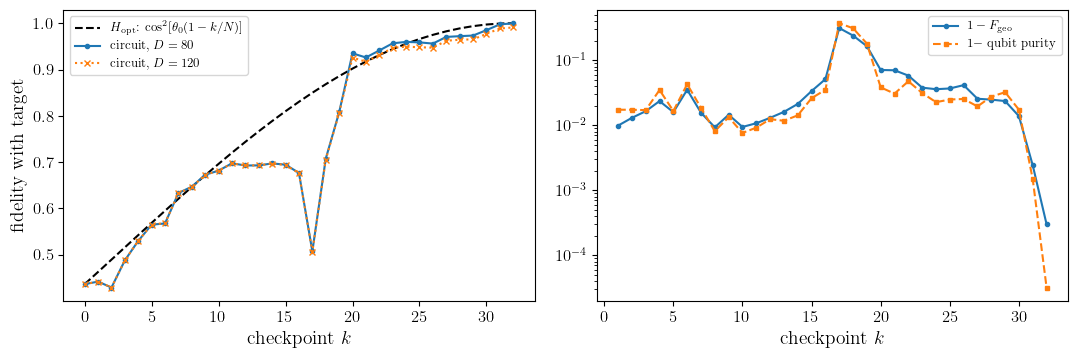

In [15]:
kx = np.arange(N_CHECK + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(kx, F_geo_target, "k--", label=r"$H_{\rm opt}$: $\cos^2[\theta_0(1-k/N)]$")
ax[0].plot(kx, F_tgt_ck, "o-", ms=3, label=f"circuit, $D={N_FOCK}$")
ax[0].plot(kx, np.asarray(osc_fidelity(target_v, ck_v)), "x:", ms=4, label=f"circuit, $D={N_FOCK_VALIDATE}$")
ax[0].set_xlabel("checkpoint $k$"); ax[0].set_ylabel("fidelity with target"); ax[0].legend(fontsize=9)
ax[1].semilogy(kx[1:], 1 - F_ck[1:], "o-", ms=3, label=r"$1 - F_{\rm geo}$")
ax[1].semilogy(kx[1:], np.clip(1 - pur_ck[1:], 1e-16, None), "s--", ms=3, label="$1 -$ qubit purity")
ax[1].set_xlabel("checkpoint $k$"); ax[1].legend(fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"fidelity_vs_geodesic_{OUT_TAG}.pdf"), bbox_inches="tight")
plt.show()

## Wigner trajectory: circuit vs $H_{\rm opt}$

Circuit states are reduced to cavity density matrices $\rho = \psi^{T}\psi^{*}$ before `utils.wigner_trajectory`. The phase-space overlap $2\pi\!\int W_c W_g$ must reproduce the state fidelity.

In [ ]:
rho_ck = np.einsum("kqm,kqn->kmn", states_ck, states_ck.conj())
xvec, yvec, Wc = wigner_trajectory(rho_ck, WIGNER_BOUND, WIGNER_BOUND, grid_points=WIGNER_POINTS)
_, _, Wg = wigner_trajectory(np.asarray(GEO), WIGNER_BOUND, WIGNER_BOUND, grid_points=WIGNER_POINTS)
dA = (xvec[1] - xvec[0]) * (yvec[1] - yvec[0])
ov = 2 * np.pi * np.sum(Wc * Wg, axis=(1, 2)) * dA
pur_c = 2 * np.pi * np.sum(Wc**2, axis=(1, 2)) * dA
rel = np.sqrt(np.sum((Wc - Wg) ** 2, axis=(1, 2)) / np.sum(Wg**2, axis=(1, 2)))

cols = sorted(set([0, N_CHECK // 4, N_CHECK // 2, (3 * N_CHECK) // 4, N_CHECK]))
vmax = float(max(np.abs(Wc).max(), np.abs(Wg).max()))
norm = mpl_colors.TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
X, Y = np.meshgrid(xvec, yvec)

fig = plt.figure(figsize=(2.8 * len(cols), 11))
gs = fig.add_gridspec(4, len(cols), height_ratios=[1, 1, 1, 0.9], hspace=0.3, wspace=0.08)
row_names = ["circuit", r"$H_{\rm opt}$", r"circuit $-$ $H_{\rm opt}$"]
for j, k in enumerate(cols):
    for r, W in enumerate((Wc[k], Wg[k], Wc[k] - Wg[k])):
        a_ = fig.add_subplot(gs[r, j])
        a_.pcolormesh(X, Y, W, cmap="RdBu_r", norm=norm, shading="gouraud", rasterized=True)
        a_.set_aspect("equal"); a_.set_xticks([]); a_.set_yticks([])
        if r == 0:
            a_.set_title(f"$k={k}/{N_CHECK}$, $t/t^*={k / N_CHECK:.2f}$", fontsize=11)
        if r == 2:
            a_.set_xlabel(f"$F={F_ck[k]:.4f}$", fontsize=10)
        if j == 0:
            a_.set_ylabel(row_names[r])
axm = fig.add_subplot(gs[3, :])
axm.plot(kx, F_ck, "o-", ms=3, label=r"$F=\sum_q|\langle g_k|\psi_k^q\rangle|^2$")
axm.plot(kx, ov, "s--", ms=3, label=r"$2\pi\int W_c W_g$")
axm.plot(kx, pur_c, "^-", ms=3, label="cavity purity")
axm.plot(kx, 1 - rel, "d:", ms=3, label=r"$1-\|W_c-W_g\|_2/\|W_g\|_2$")
axm.set_xlabel("checkpoint $k$"); axm.set_ylabel("match"); axm.grid(alpha=0.3)
axm.set_ylim(min(0.0, float((1 - rel).min())) - 0.05, 1.05)
axm.legend(fontsize=9, loc="lower center", ncol=4)
fig.savefig(os.path.join(OUT_DIR, f"wigner_match_{OUT_TAG}.pdf"), bbox_inches="tight")
plt.show()

print(f"max |Wigner overlap - F| = {np.max(np.abs(ov - F_ck)):.2e}   (grid / cutoff resolution)")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
plot_wigner(to_qarray(rho_ck[-1]), WIGNER_BOUND, WIGNER_BOUND, ax=ax[0], grid_points=WIGNER_POINTS,
            title=f"circuit, $F={F_tgt_ck[-1]:.4f}$")
plot_wigner(to_qarray(target), WIGNER_BOUND, WIGNER_BOUND, ax=ax[1], grid_points=WIGNER_POINTS,
            title="target")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"wigner_final_{OUT_TAG}.pdf"), bbox_inches="tight")
plt.show()

## Fubini-Study arc length vs the Mandelstam-Tamm geodesic

Every gate is interpolated (`PATH_FRAMES_PER_GATE` sub-steps) and the joint qubit-cavity path length $\mathcal{L}_{\rm FS} = \sum_i \arccos|\braket{\Psi_i|\Psi_{i+1}}|$ is compared against $\theta_0$, the length of the $H_{\rm opt}$ geodesic. $\mathcal{L}_{\rm FS}/\theta_0 \ge 1$ is the circuit's excess over the speed limit (qubit rotations included).

theta0 (geodesic)    = 0.84912
L_FS (circuit, joint) = 91.13129   ratio L_FS/theta0 = 107.325
Bures angle vacuum -> circuit endpoint (joint) = 1.06721   ratio L_FS/that = 85.392
   contribution of R    : 11.51062
   contribution of sqA  : 38.74466
   contribution of sqB  : 40.87601


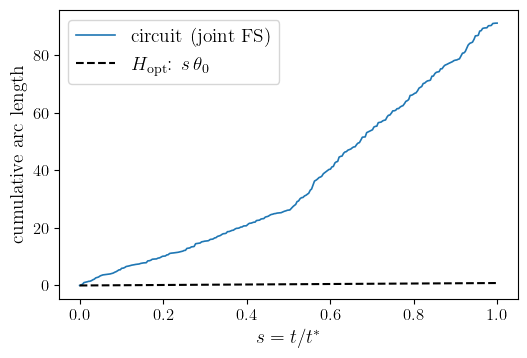

In [16]:
def interpolated_path(ansatz, flat, m):
    # returns (s, psi) after every interpolated sub-gate; s = geodesic fraction
    P = np.asarray(flat).reshape(ansatz.n_blocks, ansatz.n_col)
    n_g = ansatz.n_gen + 1
    psi = ansatz.psi_init()
    s_out, psi_out, lab = [0.0], [np.asarray(psi)], ["vacuum"]
    fr = np.linspace(0, 1, m + 1)[1:]
    for b, p in enumerate(P):
        th, ph = p[ansatz.n_gen], p[ansatz.n_gen + 1]
        for f in fr:
            s_out.append((b + f / n_g) / ansatz.n_blocks)
            psi_out.append(np.asarray(qubit_rotation(f * th, ph) @ psi)); lab.append("R")
        psi = qubit_rotation(th, ph) @ psi
        for j in range(ansatz.n_gen):
            for f in fr:
                s_out.append((b + (j + 1 + f) / n_g) / ansatz.n_blocks)
                psi_out.append(np.asarray(ansatz.apply_cond(psi, j, f * p[j]))); lab.append(ansatz.generators[j])
            psi = ansatz.apply_cond(psi, j, p[j])
    return np.array(s_out), np.stack(psi_out), lab


s_path, psi_path, lab_path = interpolated_path(ansatz, best_x, PATH_FRAMES_PER_GATE)
flat_path = psi_path.reshape(len(psi_path), -1)
steps = np.arccos(np.clip(np.abs(np.sum(flat_path[:-1].conj() * flat_path[1:], axis=1)), 0, 1))
L_fs = np.concatenate([[0.0], np.cumsum(steps)])
print(f"theta0 (geodesic)    = {theta0:.5f}")
theta_end = float(np.arccos(np.clip(np.abs(np.vdot(flat_path[0], flat_path[-1])), 0, 1)))
print(f"L_FS (circuit, joint) = {L_fs[-1]:.5f}   ratio L_FS/theta0 = {L_fs[-1] / theta0:.3f}")
print(f"Bures angle vacuum -> circuit endpoint (joint) = {theta_end:.5f}   ratio L_FS/that = {L_fs[-1] / theta_end:.3f}")
for g in ("R",) + tuple(GENERATORS):
    sel = np.array(lab_path[1:]) == g
    print(f"   contribution of {g:5s}: {steps[sel].sum():.5f}")

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(s_path, L_fs, lw=1.2, label="circuit (joint FS)")
ax.plot([0, 1], [0, theta0], "k--", label=r"$H_{\rm opt}$: $s\,\theta_0$")
ax.set_xlabel(r"$s = t/t^*$"); ax.set_ylabel("cumulative arc length"); ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, f"arclength_{OUT_TAG}.pdf"), bbox_inches="tight")
plt.show()

## Movie (optional): circuit vs $H_{\rm opt}$ at every interpolated gate

In [17]:
# ---- movie settings -------------------------------------------------------
MOVIE_MAX_FRAMES = 240          # total frames (subsampled from the interpolated gate path)
MOVIE_FRAMES_PER_GATE = 2
MOVIE_POINTS = 121
MOVIE_FPS = 12
MOVIE_HOLD_S = 2.0              # seconds to hold the final frame
MOVIE_PATH = os.path.join(OUT_DIR, f"wigner_gates_vs_brachistochrone_{OUT_TAG}.mp4")

t_start = time.time()

# ---- 1. gate-sequence path, every gate interpolated, then subsampled -------
s_m, psi_m, lab_m = interpolated_path(ansatz, best_x, MOVIE_FRAMES_PER_GATE)
stride = max(1, int(np.ceil(len(s_m) / MOVIE_MAX_FRAMES)))
keep = np.unique(np.r_[np.arange(0, len(s_m), stride), len(s_m) - 1])
s_m, psi_m, lab_m = s_m[keep], psi_m[keep], [lab_m[i] for i in keep]
n_frames = len(s_m)

# ---- 2. brachistochrone: integrate H_opt from vacuum on t = s * t* ---------
tlist = jnp.asarray(s_m * theta0)                      # ||H_opt|| = 1  ->  t* = theta0
sim = jqt.sesolve(to_qarray(H_opt), jqt.basis(N_FOCK, 0), tlist)
sim_q = sim if isinstance(sim, jqt.Qarray) else sim.states   # no hasattr on Qarray
psi_sim = np.asarray(sim_q.data).reshape(n_frames, N_FOCK)

geo_ref = np.asarray(geodesic(s_m))
dev = np.max(1 - np.abs(np.sum(geo_ref.conj() * psi_sim, axis=1)) ** 2)
print(f"sesolve vs analytic geodesic: max infidelity {dev:.1e}")

# ---- 3. Wigner functions with utils.wigner_trajectory ---------------------
rho_m = np.einsum("tqm,tqn->tmn", psi_m, psi_m.conj())       # trace out the qubit
xm, ym, Wc_m = wigner_trajectory(rho_m, WIGNER_BOUND, WIGNER_BOUND, grid_points=MOVIE_POINTS)
_, _, Wb_m = wigner_trajectory(psi_sim, WIGNER_BOUND, WIGNER_BOUND, grid_points=MOVIE_POINTS)
Wc_m = np.ascontiguousarray(np.real(Wc_m), dtype=np.float32)
Wb_m = np.ascontiguousarray(np.real(Wb_m), dtype=np.float32)
print(f"Wigner frames: 2 x {n_frames} in {time.time() - t_start:.1f}s")

F_cb = np.asarray(osc_fidelity(jnp.asarray(psi_sim), jnp.asarray(psi_m)))   # circuit vs H_opt
F_ct = np.asarray(osc_fidelity(target, jnp.asarray(psi_m)))                 # circuit vs target
F_bt = np.abs(psi_sim @ np.asarray(target).conj()) ** 2                     # H_opt vs target

# ---- 4. draw with plot_wigner, then animate in place ----------------------
with plt.rc_context({"text.usetex": False}):
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.8))
    plot_wigner(wigner=Wc_m[0], xvec=xm, yvec=ym, ax=axs[0], title="optimized gate sequence")
    plot_wigner(wigner=Wb_m[0], xvec=xm, yvec=ym, ax=axs[1], title=r"brachistochrone $H_{\rm opt}$")

    vm = float(max(np.abs(Wc_m).max(), np.abs(Wb_m).max()))
    shared = mpl_colors.TwoSlopeNorm(vmin=-vm, vcenter=0.0, vmax=vm)
    meshes = [ax.collections[0] for ax in axs]          # QuadMesh from plot_wigner
    for mesh in meshes:
        mesh.set_norm(shared)                           # fixed scale; colorbars follow
    sup = fig.suptitle("", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.9))

    hold = int(MOVIE_HOLD_S * MOVIE_FPS)
    order = list(range(n_frames)) + [n_frames - 1] * hold

    def update(i):
        k = order[i]
        meshes[0].set_array(Wc_m[k].ravel())
        meshes[1].set_array(Wb_m[k].ravel())
        sup.set_text(
            f"$t/t^* = {s_m[k]:.3f}$   (gate: {lab_m[k]})\n"
            f"$F$(circuit, $H_{{\\rm opt}}$) = {F_cb[k]:.4f}    "
            f"$F$(circuit, target) = {F_ct[k]:.4f}    "
            f"$F$($H_{{\\rm opt}}$, target) = {F_bt[k]:.4f}"
        )
        return (*meshes, sup)

    anim = FuncAnimation(fig, update, frames=len(order), blit=False)
    os.makedirs(os.path.dirname(os.path.abspath(MOVIE_PATH)), exist_ok=True)
    if MOVIE_PATH.endswith(".gif"):
        anim.save(MOVIE_PATH, writer=PillowWriter(fps=MOVIE_FPS), dpi=100)
    else:
        from matplotlib.animation import FFMpegWriter
        anim.save(MOVIE_PATH, writer=FFMpegWriter(
            fps=MOVIE_FPS, codec="libx264", bitrate=-1,
            extra_args=["-pix_fmt", "yuv420p", "-preset", "fast", "-crf", "18"]), dpi=150)
    update(len(order) - 1)
    fig.savefig(MOVIE_PATH.rsplit(".", 1)[0] + "_final.pdf", bbox_inches="tight")
    plt.close(fig)

print(f"saved {MOVIE_PATH}  ({len(order)} frames, {time.time() - t_start:.1f}s total)")

100% |█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| [00:00<00:00, 48477.85%/s]


sesolve vs analytic geodesic: max infidelity 7.5e-09
Wigner frames: 2 x 193 in 96.1s
saved ../../figs/timeopt_tracking/wigner_gates_vs_brachistochrone_operator_L0_D80_N32_K3_Delta0.35_sqA-sqB.mp4  (217 frames, 152.7s total)
